In [30]:
# Inventário nacional e por UF. Cada recorte municipal será uma instância.
from pathlib import Path
import pandas as pd
import numpy as np
import pyogrio
import matplotlib.pyplot as plt

In [31]:
arquivo_br = Path("data/BR_setores_CD2022.gpkg")
pasta_outputs = Path("outputs") / "brasil"
pasta_outputs.mkdir(parents=True, exist_ok=True)

pyogrio.list_layers(arquivo_br)

array([['BR_setores_CD2022', 'Polygon']], dtype=object)

In [32]:
# Sem carregar geometrias, usa menos memória.
colunas = [
    "CD_SETOR", "CD_MUN", "NM_MUN", "CD_UF", "NM_UF",
    "SITUACAO", "CD_SIT", "CD_TIPO", "AREA_KM2", "v0001",
]
br_registros = pyogrio.read_dataframe(
    arquivo_br, layer="BR_setores_CD2022",
    columns=colunas, read_geometry=False,
)

br_registros.head()

,CD_SETOR,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_UF,NM_UF,CD_MUN,NM_MUN,v0001
0,110001505000002,Urbana,1,0,0.539310,11,Rondônia,1100015,Alta Floresta D'Oeste,928
1,110001505000003,Urbana,1,0,0.236218,11,Rondônia,1100015,Alta Floresta D'Oeste,556
2,110001505000004,Urbana,1,0,0.211867,11,Rondônia,1100015,Alta Floresta D'Oeste,222
3,110001505000006,Urbana,1,0,0.505448,11,Rondônia,1100015,Alta Floresta D'Oeste,785
4,110001505000007,Urbana,1,0,0.299042,11,Rondônia,1100015,Alta Floresta D'Oeste,748


In [33]:
resumo_registros = pd.Series({
    "Registros originais": len(br_registros),
    "Códigos de setor distintos": br_registros["CD_SETOR"].nunique(),
    "Repetições além da primeira": br_registros["CD_SETOR"].duplicated().sum(),
})

resumo_registros

Registros originais            472780
Códigos de setor distintos     468099
Repetições além da primeira      4681
dtype: int64

In [34]:
br = br_registros.drop_duplicates().copy()
conflitos = br.loc[br["CD_SETOR"].duplicated(keep=False)]

print("Setores com atributos conflitantes:", conflitos["CD_SETOR"].nunique())
if not conflitos.empty:
    raise ValueError("Investigar atributos conflitantes antes de agregar a população.")


Setores com atributos conflitantes: 0


In [35]:
# Indicadores de qualidade são reutilizados por UF e município.
br["populacao"] = br["v0001"]
br["codigo_setor_ausente"] = br["CD_SETOR"].fillna("").str.strip().eq("")
br["codigo_municipio_ausente"] = br["CD_MUN"].fillna("").str.strip().eq("")
br["codigo_uf_ausente"] = br["CD_UF"].fillna("").str.strip().eq("")
br["area_inadequada"] = br["AREA_KM2"].isna() | br["AREA_KM2"].le(0)
br["populacao_inadequada"] = (
    br["populacao"].isna() | br["populacao"].lt(0) | br["populacao"].mod(1).ne(0)
)

In [36]:
colunas_qualidade = [
    "codigo_setor_ausente", "codigo_municipio_ausente", "codigo_uf_ausente",
    "area_inadequada", "populacao_inadequada",
]
qualidade_nacional = br[colunas_qualidade].sum().rename("setores_com_ocorrencia")

qualidade_nacional

codigo_setor_ausente        0
codigo_municipio_ausente    0
codigo_uf_ausente           0
area_inadequada             0
populacao_inadequada        0
Name: setores_com_ocorrencia, dtype: int64

In [37]:
br["situacao_analise"] = br["SITUACAO"].copy()
br.loc[br["CD_SIT"].eq("9"), "situacao_analise"] = "Massas de água"

resumo_classificacao = br.groupby("situacao_analise", dropna=False).agg(
    setores=("CD_SETOR", "count"), populacao=("populacao", "sum"),
)
resumo_classificacao

,setores,populacao
situacao_analise,,
Massas de água,1101,0
Rural,112031,25572339
Urbana,354965,177508417
NaN,2,0


In [38]:
# O recorte inclui urbanos e rurais, todos os tipos e setores de população zero.
br_analise = br.loc[br["situacao_analise"].isin(["Urbana", "Rural"])].copy()
fora_recorte = br.loc[~br["situacao_analise"].isin(["Urbana", "Rural"])]

print("Setores urbanos e rurais:", len(br_analise))
print("População fora do recorte:", fora_recorte["populacao"].sum())

Setores urbanos e rurais: 466996
População fora do recorte: 0


In [39]:
# Candidatos incluem setores urbanos e rurais sem população; demanda positiva é separada.
br_analise["demanda_positiva"] = br_analise["populacao"].gt(0)
br_analise["populacao_rural"] = br_analise["populacao"].where(
    br_analise["situacao_analise"].eq("Rural"), 0,
)
br_analise["area_rural_km2"] = br_analise["AREA_KM2"].where(
    br_analise["situacao_analise"].eq("Rural"), 0,
)

In [40]:
# Códigos identificam os recortes.
resumo_municipios = br_analise.groupby(
    ["CD_UF", "CD_MUN", "NM_MUN"], dropna=False,
).agg(
    setores=("CD_SETOR", "count"),
    origens_demanda_positiva=("demanda_positiva", "sum"),
    populacao=("populacao", "sum"),
    area_km2=("AREA_KM2", "sum"),
    populacao_rural=("populacao_rural", "sum"),
    area_rural_km2=("area_rural_km2", "sum"),
)

In [41]:
# Participações rurais descrevem população e território, separadamente.
resumo_municipios["populacao_rural_percentual"] = (
    100 * resumo_municipios["populacao_rural"] / resumo_municipios["populacao"].where(resumo_municipios["populacao"].gt(0))
)
resumo_municipios["area_rural_percentual"] = (
    100 * resumo_municipios["area_rural_km2"] / resumo_municipios["area_km2"]
)
resumo_municipios["densidade_hab_km2"] = resumo_municipios["populacao"] / resumo_municipios["area_km2"]

resumo_municipios.head().round(2)


setores  origens_demanda_positiva  \
CD_UF CD_MUN  NM_MUN                                                     
11    1100015 Alta Floresta D'Oeste       85                        80   
      1100023 Ariquemes                  169                       169   
      1100031 Cabixi                      20                        20   
      1100049 Cacoal                     187                       184   
      1100056 Cerejeiras                  34                        33   

                                     populacao  area_km2  populacao_rural  \
CD_UF CD_MUN  NM_MUN                                                        
11    1100015 Alta Floresta D'Oeste      21494   7067.13             8523   
      1100023 Ariquemes                  96833   4426.14            12881   
      1100031 Cabixi                      5351   1314.35             2505   
      1100049 Cacoal                     86887   3793.00            14980   
      1100056 Cerejeiras                 15890   2783.30             1774   

                                     area_rural_km2  \
CD_UF CD_MUN  NM_MUN                                  
11    1100015 Alta Floresta D'Oeste         7056.40   
      1100023 Ariquemes                     4385.05   
      1100031 Cabixi                        1312.50   
      1100049 Cacoal                        3744.76   
      1100056 Cerejeiras                    2768.53   

                                     populacao_rural_percentual  \
CD_UF CD_MUN  NM_MUN                                              
11    1100015 Alta Floresta D'Oeste                       39.65   
      1100023 Ariquemes                                   13.30   
      1100031 Cabixi                                      46.81   
      1100049 Cacoal                                      17.24   
      1100056 Cerejeiras                                  11.16   

                                     area_rural_percentual  densidade_hab_km2  
CD_UF CD_MUN  NM_MUN                                                           
11    1100015 Alta Floresta D'Oeste                  99.85               3.04  
      1100023 Ariquemes                              99.07              21.88  
      1100031 Cabixi                                 99.86               4.07  
      1100049 Cacoal                                 98.73              22.91  
      1100056 Cerejeiras                             99.47               5.71

In [42]:
# n² é a previsão com todos os setores urbanos e rurais como origens e candidatos.
# Zero demanda pode ser omitida na modelagem. Não removi esses candidatos.
resumo_municipios["pares_distancias"] = resumo_municipios["setores"] ** 2
resumo_municipios["memoria_matriz_gib"] = resumo_municipios["pares_distancias"] * 8 / 1024 ** 3

resumo_municipios.nlargest(10, "setores").round(2)

,,,setores,origens_demanda_positiva,populacao,area_km2,populacao_rural,area_rural_km2,populacao_rural_percentual,area_rural_percentual,densidade_hab_km2,pares_distancias,memoria_matriz_gib
CD_UF,CD_MUN,NM_MUN,,,,,,,,,,,
35,3550308,São Paulo,27291,26889,11451999,1466.62,17213,457.28,0.15,31.18,7808.45,744798681,5.55
33,3304557,Rio de Janeiro,13777,13474,6211223,1180.39,59,10.23,0.00,0.87,5262.00,189805729,1.41
53,5300108,Brasília,5414,5342,2817381,5713.98,99299,4767.56,3.52,83.44,493.07,29311396,0.22
31,3106200,Belo Horizonte,5166,5137,2315560,331.35,0,0.00,0.00,0.00,6988.18,26687556,0.20
29,2927408,Salvador,4541,4504,2417678,307.33,0,0.00,0.00,0.00,7866.77,20620681,0.15
23,2304400,Fortaleza,4407,4306,2428708,312.31,0,0.00,0.00,0.00,7776.47,19421649,0.14
13,1302603,Manaus,3280,3229,2063689,10321.11,20012,9764.77,0.97,94.61,199.95,10758400,0.08
41,4106902,Curitiba,3190,3178,1773718,434.89,0,0.00,0.00,0.00,4078.52,10176100,0.08
26,2611606,Recife,2834,2814,1488920,214.82,0,0.00,0.00,0.00,6931.15,8031556,0.06


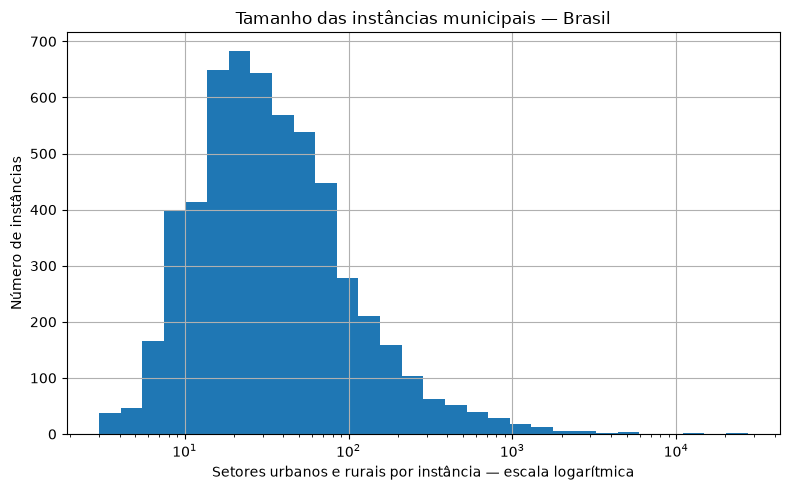

In [43]:
tamanhos = resumo_municipios["setores"]
faixas = np.geomspace(tamanhos.min(), tamanhos.max() + 1, 31)
fig, ax = plt.subplots(figsize=(8, 5))
tamanhos.hist(bins=faixas, ax=ax)
ax.set_xscale("log")
ax.set_title("Tamanho das instâncias municipais — Brasil")
ax.set_xlabel("Setores urbanos e rurais por instância — escala logarítmica")
ax.set_ylabel("Número de instâncias")
plt.tight_layout()
fig.savefig(pasta_outputs / "distribuicao_tamanho_instancias.svg", bbox_inches="tight")
plt.show()


In [44]:
# Por UF, instâncias municipais. Não crio um problema estadual único.
resumo_ufs = resumo_municipios.groupby(level="CD_UF").agg(
    instancias=("setores", "count"),
    setores=("setores", "sum"),
    origens_demanda_positiva=("origens_demanda_positiva", "sum"),
    populacao=("populacao", "sum"),
    area_km2=("area_km2", "sum"),
    populacao_rural=("populacao_rural", "sum"),
    area_rural_km2=("area_rural_km2", "sum"),
    mediana_setores_instancia=("setores", "median"),
    maior_instancia_setores=("setores", "max"),
)


In [ ]:
nomes_ufs = br[["CD_UF", "NM_UF"]].drop_duplicates().set_index("CD_UF")["NM_UF"]
resumo_ufs.insert(0, "nome_uf", resumo_ufs.index.map(nomes_ufs))
resumo_ufs["populacao_rural_percentual"] = 100 * resumo_ufs["populacao_rural"] / resumo_ufs["populacao"]
resumo_ufs["area_rural_percentual"] = 100 * resumo_ufs["area_rural_km2"] / resumo_ufs["area_km2"]
resumo_ufs["densidade_hab_km2"] = resumo_ufs["populacao"] / resumo_ufs["area_km2"]

# Dispersão do tamanho das instâncias e concentração populacional por UF.
resumo_ufs["p90_setores_instancia"] = resumo_municipios.groupby(level="CD_UF")["setores"].quantile(0.90)
resumo_ufs["populacao_maior_municipio_percentual"] = (
    100 * resumo_municipios.groupby(level="CD_UF")["populacao"].max() / resumo_ufs["populacao"]
)

resumo_ufs.round(2)

,nome_uf,instancias,setores,origens_demanda_positiva,populacao,area_km2,populacao_rural,area_rural_km2,mediana_setores_instancia,maior_instancia_setores,populacao_rural_percentual,area_rural_percentual,densidade_hab_km2,p90_setores_instancia,populacao_maior_municipio_percentual
CD_UF,,,,,,,,,,,,,,,
11,Rondônia,52,3456,3304,1581196,237754.17,339524,236967.00,34.5,796,21.47,99.67,6.65,129.8,29.12
12,Acre,22,2215,2127,830018,164172.95,212076,163646.70,54.0,669,25.55,99.68,5.06,164.4,43.95
13,Amazonas,62,10674,9602,3941613,1548190.02,676639,1546744.04,107.5,3280,17.17,99.91,2.55,225.8,52.36
14,Roraima,15,1769,1612,636707,222674.72,138937,222432.16,92.0,542,21.82,99.89,2.86,206.8,64.94
15,Pará,144,16494,16065,8120131,1223839.60,2024601,1220767.66,66.5,2058,24.93,99.75,6.63,223.8,16.05
16,Amapá,16,1477,1440,733759,141045.71,82505,140788.41,27.5,771,11.24,99.82,5.20,152.5,60.36
17,Tocantins,139,4111,4029,1511460,276920.89,258653,275970.92,15.0,732,17.11,99.66,5.46,47.0,20.03
21,Maranhão,217,16268,16030,6776699,329295.68,1969709,326172.72,45.0,1733,29.07,99.05,20.58,131.8,15.31
22,Piauí,224,7331,7278,3271199,251714.65,999815,250119.51,16.0,1530,30.56,99.37,13.00,54.7,26.48


In [53]:
# UFs dos casos detalhados. A mesma análise pode ser feita para qualquer UF.
comparacao_ufs = resumo_ufs.loc[["31", "35", "53"], [
    "nome_uf", "instancias", "populacao", "mediana_setores_instancia",
    "p90_setores_instancia", "maior_instancia_setores",
    "populacao_rural_percentual", "area_rural_percentual",
    "populacao_maior_municipio_percentual",
]]
comparacao_ufs.round(2)


,nome_uf,instancias,populacao,mediana_setores_instancia,p90_setores_instancia,maior_instancia_setores,populacao_rural_percentual,area_rural_percentual,populacao_maior_municipio_percentual
CD_UF,,,,,,,,,
31,Minas Gerais,853,20539989,25.0,98.0,5166,11.77,98.40,11.27
35,São Paulo,645,44411238,37.0,295.6,27291,3.18,94.92,25.79
53,Distrito Federal,1,2817381,5414.0,5414.0,5414,3.52,83.44,100.00


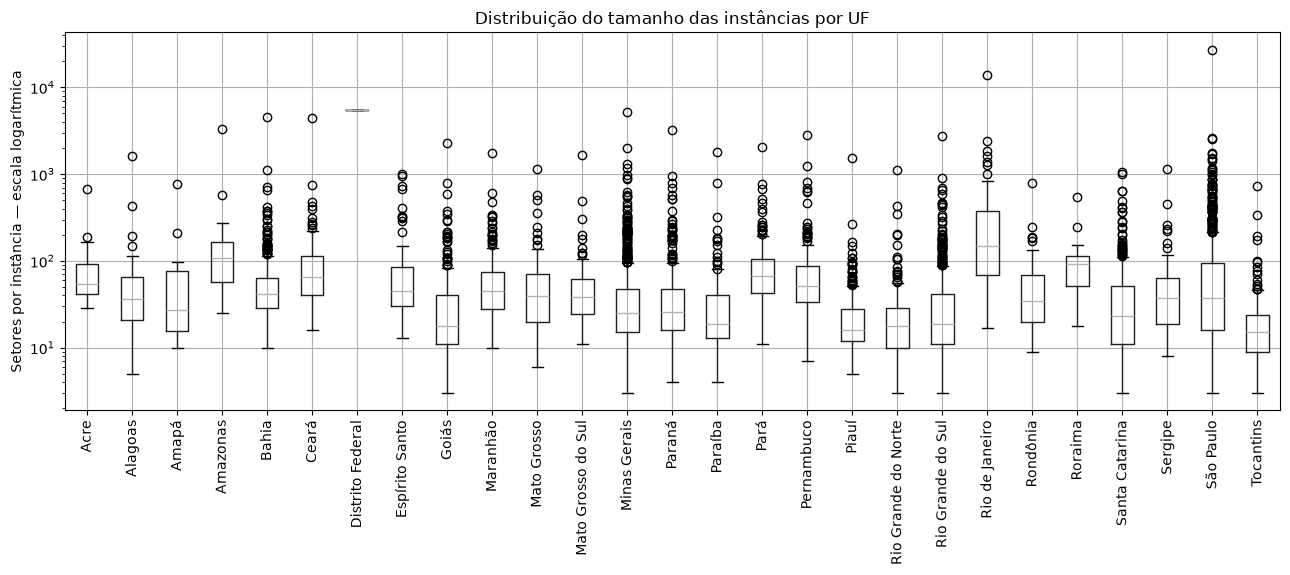

In [ ]:
# Cada caixa descreve os municípios da UF. DF possui somente um recorte.
dados_boxplot = resumo_municipios.reset_index()
dados_boxplot["nome_uf"] = dados_boxplot["CD_UF"].map(nomes_ufs)
fig, ax = plt.subplots(figsize=(13, 6))
dados_boxplot.boxplot(column="setores", by="nome_uf", ax=ax, rot=90)
ax.set_yscale("log")
ax.set_title("Distribuição do tamanho das instâncias por UF")
ax.set_xlabel("")
ax.set_ylabel("Setores por instância — escala logarítmica")
fig.suptitle("")
plt.tight_layout()
fig.savefig(pasta_outputs / "tamanho_instancias_por_uf.svg", bbox_inches="tight")
plt.show()


In [ ]:
# Qualidade dos atributos em todo o arquivo, incluindo registros fora do recorte.
qualidade_ufs = br.groupby(["CD_UF", "NM_UF"], dropna=False)[colunas_qualidade].sum()

qualidade_ufs

,,codigo_setor_ausente,codigo_municipio_ausente,codigo_uf_ausente,area_inadequada,populacao_inadequada
CD_UF,NM_UF,,,,,
11,Rondônia,0,0,0,0,0
12,Acre,0,0,0,0,0
13,Amazonas,0,0,0,0,0
14,Roraima,0,0,0,0,0
15,Pará,0,0,0,0,0
16,Amapá,0,0,0,0,0
17,Tocantins,0,0,0,0,0
21,Maranhão,0,0,0,0,0
22,Piauí,0,0,0,0,0


In [ ]:
# Uma contagem municipal de setores com problemas. Cada setor é contado uma vez.
br["atributos_com_pendencia"] = br[colunas_qualidade].any(axis=1)
pendencias_municipais = br.groupby(
    ["CD_UF", "CD_MUN", "NM_MUN"], dropna=False,
)["atributos_com_pendencia"].sum()

pendencias_municipais.loc[pendencias_municipais.gt(0)]


Series([], Name: atributos_com_pendencia, dtype: int64)

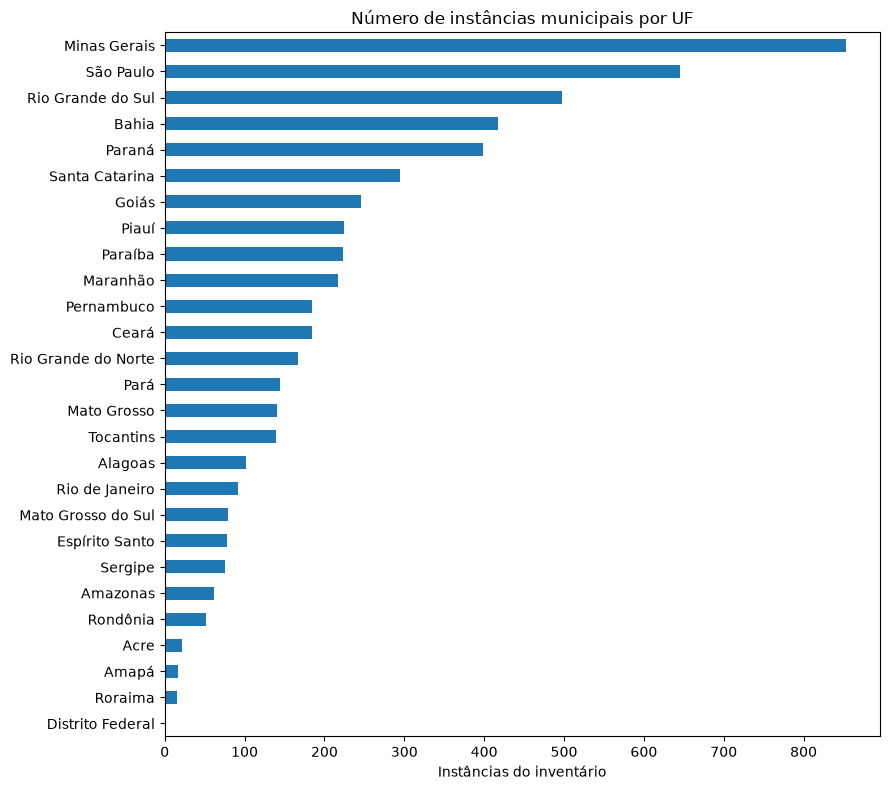

In [50]:
fig, ax = plt.subplots(figsize=(9, 8))
resumo_ufs.sort_values("instancias").plot.barh(
    x="nome_uf", y="instancias", ax=ax, legend=False,
)
ax.set_title("Número de instâncias municipais por UF")
ax.set_xlabel("Instâncias do inventário")
ax.set_ylabel("")
plt.tight_layout()
fig.savefig(pasta_outputs / "instancias_por_uf.svg", bbox_inches="tight")
plt.show()


In [ ]:
# Síntese: cobertura, qualidade de atributos e escala prevista.
resumo_nacional = pd.Series({
    "Ano dos dados": 2022,
    "Registros originais": len(br_registros),
    "Setores distintos": len(br),
    "Setores urbanos e rurais": len(br_analise),
    "Origens com demanda positiva": br_analise["demanda_positiva"].sum(),
    "Instâncias municipais ou equivalentes": len(resumo_municipios),
    "UFs no inventário": len(resumo_ufs),
    "População dos setores urbanos e rurais": br_analise["populacao"].sum(),
    "Municípios com pendências de atributos": pendencias_municipais.gt(0).sum(),
})

resumo_nacional

Ano dos dados                                  2022
Registros originais                          472780
Setores distintos                            468099
Setores urbanos e rurais                     466996
Origens com demanda positiva                 458772
Instâncias municipais ou equivalentes          5570
UFs no inventário                                27
População dos setores urbanos e rurais    203080756
Municípios com pendências de atributos            0
dtype: int64